# Week 2 Day 3: Feature Engineering on the Loan Dataset

Input: `data/cleaned_loan_dataset.csv` (output of W2D2, no missing values).

## New features
| Feature | Type | How it is built | Why it should help |
|---------|------|-----------------|--------------------|
| `TotalIncome` | sum | `ApplicantIncome + CoapplicantIncome` | Lenders judge repayment ability on household income, not only the applicant's |
| `LoanAmount_to_Income` (feature_1) | ratio | `LoanAmount / TotalIncome` | A large loan matters only relative to income; a ratio captures affordability |
| `LogTotalIncome` | log transform | `log1p(TotalIncome)` | Income is heavily right-skewed; the log compresses outliers for scaling and models |
| `Income_Band` (feature_2) | binned | `qcut` of `TotalIncome` into 4 equal-sized bands | A coarse, robust version of income that tree models and EDA can use easily |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path("data/cleaned_loan_dataset.csv"), Path("../data/cleaned_loan_dataset.csv")]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    import os
    raise FileNotFoundError(f"CSV not found. Current folder is: {os.getcwd()}")

df = pd.read_csv(csv_path)
df["Loan_Status_num"] = (df["Loan_Status"] == "Y").astype(int)
df.shape

(614, 14)

## 1. Create the features

In [2]:
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["LoanAmount_to_Income"] = df["LoanAmount"] / df["TotalIncome"]
df["LogTotalIncome"] = np.log1p(df["TotalIncome"])
df["Income_Band"] = pd.qcut(
    df["TotalIncome"], 4, labels=["Low", "Medium", "High", "Very High"]
)

df[["ApplicantIncome", "CoapplicantIncome", "TotalIncome",
    "LoanAmount_to_Income", "LogTotalIncome", "Income_Band"]].head()

,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount_to_Income,LogTotalIncome,Income_Band
0,5849,0.0,5849.0,0.021884,8.674197,High
1,4583,1508.0,6091.0,0.021015,8.714732,High
2,3000,0.0,3000.0,0.022000,8.006701,Low
3,2583,2358.0,4941.0,0.024287,8.505525,Medium
4,6000,0.0,6000.0,0.023500,8.699681,High


## 2. Re-run EDA on the new features
### Skew before and after the log transform

ApplicantIncome         6.54
TotalIncome             5.63
LogTotalIncome          1.08
LoanAmount_to_Income    1.18
dtype: float64


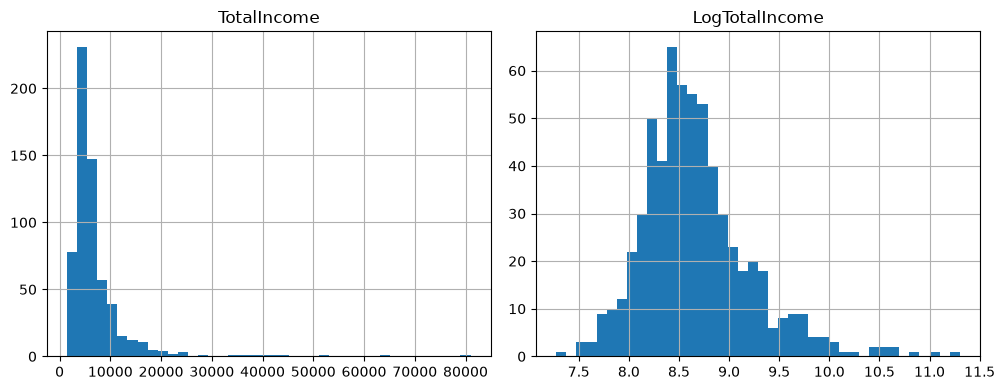

In [3]:
print(df[["ApplicantIncome", "TotalIncome", "LogTotalIncome", "LoanAmount_to_Income"]].skew().round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["TotalIncome"].hist(bins=40, ax=axes[0]); axes[0].set_title("TotalIncome")
df["LogTotalIncome"].hist(bins=40, ax=axes[1]); axes[1].set_title("LogTotalIncome")
plt.tight_layout()
plt.show()

### Correlation with the target (approved = 1)

In [4]:
cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "TotalIncome",
        "LogTotalIncome", "LoanAmount_to_Income", "Credit_History"]
print(df[cols + ["Loan_Status_num"]].corr()["Loan_Status_num"].drop("Loan_Status_num").round(3))

ApplicantIncome        -0.005
CoapplicantIncome      -0.059
LoanAmount             -0.033
TotalIncome            -0.031
LogTotalIncome          0.007
LoanAmount_to_Income   -0.086
Credit_History          0.541
Name: Loan_Status_num, dtype: float64


### Approval rate by income band

              mean  count
Income_Band              
Low          0.677    155
Medium       0.684    152
High         0.712    153
Very High    0.675    154


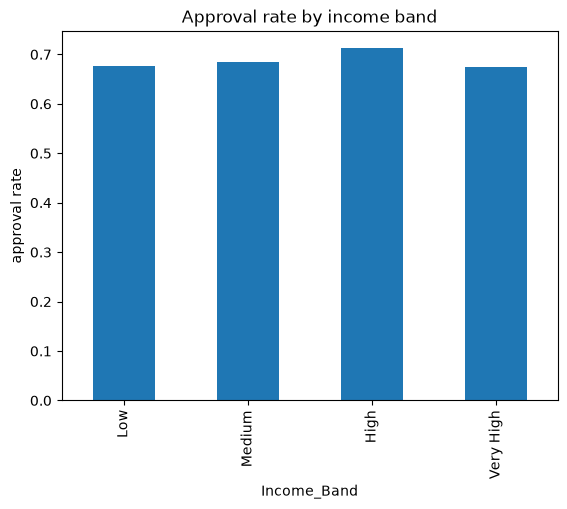

In [5]:
rate = df.groupby("Income_Band", observed=True)["Loan_Status_num"].agg(["mean", "count"]).round(3)
print(rate)
rate["mean"].plot(kind="bar", title="Approval rate by income band")
plt.ylabel("approval rate")
plt.show()

## 3. Findings
- The log transform works as intended: skew drops from 6.5 (`ApplicantIncome`) and 5.6 (`TotalIncome`) to 1.1 (`LogTotalIncome`), which will help scaling in W2D4.
- `LoanAmount_to_Income` is the best of the new features for approval (correlation -0.09), slightly stronger than any raw income column (all within ±0.06). Higher ratios mean slightly lower approval, as expected.
- `Income_Band` shows almost no signal: approval rates are 68%, 68%, 71% and 68% across the four bands.
- Overall the new features add only weak signal. `Credit_History` (correlation 0.54) remains by far the strongest predictor, so income-based features are mainly useful for cleaner distributions and for combining with credit history in later models.

In [6]:
out_path = csv_path.parent / "featured_loan_dataset.csv"
df.drop(columns=["Loan_Status_num"]).to_csv(out_path, index=False)
print("Saved", out_path, df.shape)

Saved ..\data\featured_loan_dataset.csv (614, 18)
